In [16]:
%pip install scikit-learn plotly


   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 1.6 MB/s eta 0:00:06
   ---- ----------------------------------- 1.0/9.7 MB 2.4 MB/s eta 0:00:04
   --------- ------------------------------ 2.4/9.7 MB 3.6 MB/s eta 0:00:03
   -------------------- ------------------- 5.0/9.7 MB 5.9 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 9.4 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\Fast\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsClassifier

In [31]:
import os
os.makedirs("images", exist_ok=True)

def save_plotly(fig, name):
    """Save a Plotly figure as a static PNG for the README."""
    try:
        fig.write_image(f"images/{name}.png", scale=2, width=1000, height=550)
    except Exception as e:
        print(f"Could not save {name}: {e}\nInstall with: pip install -U kaleido")

def save_plt(name):
    """Save the current Matplotlib/Seaborn figure. Call BEFORE plt.show()."""
    plt.savefig(f"images/{name}.png", dpi=200, bbox_inches="tight")

In [18]:
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

In [19]:
TRAIN_PATH = "customer_churn_dataset-training-master.csv"
TEST_PATH  = "customer_churn_dataset-testing-master.csv"

In [20]:
# Features that describe behaviour (NOT the churn label)
FEATURES = ["Usage Frequency", "Last Interaction", "Support Calls", "Payment Delay"]


In [21]:
# Business settings (tune these, they are decision levers)
N_CLUSTERS_OVERRIDE = None   # set an int to force k, otherwise chosen automatically
KNN_NEIGHBORS       = 25
DRIFT_THRESHOLD     = 0.40   # share of neighbours in high-risk group that triggers a flag
CAPACITY_PER_WEEK   = 500    # how many accounts the managers can actually call


## Load and clean

In [22]:
def load(path):
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    df = df.dropna().drop_duplicates(subset="CustomerID").reset_index(drop=True)
    df["Churn"] = df["Churn"].astype(int)
    return df

train = load(TRAIN_PATH)
test  = load(TEST_PATH)

print("Train:", train.shape, "| Test:", test.shape)
print("Train churn rate: {:.1%} | Test churn rate: {:.1%}".format(
    train["Churn"].mean(), test["Churn"].mean()))


Train: (440832, 12) | Test: (64374, 12)
Train churn rate: 56.7% | Test churn rate: 47.4%


## EDA

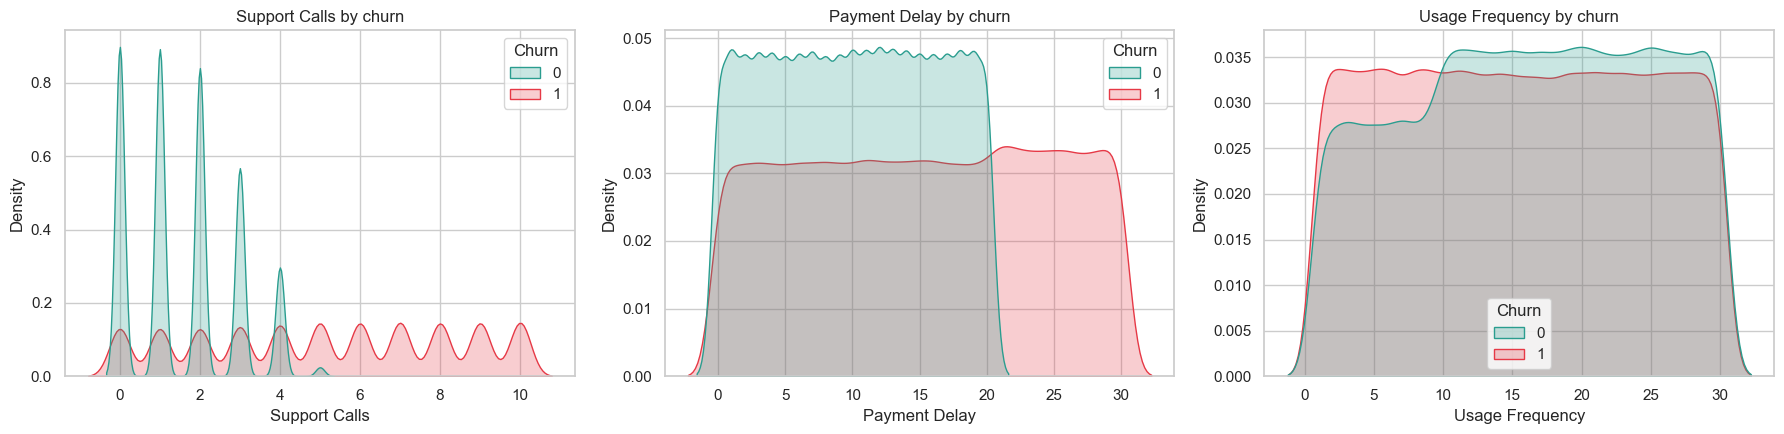

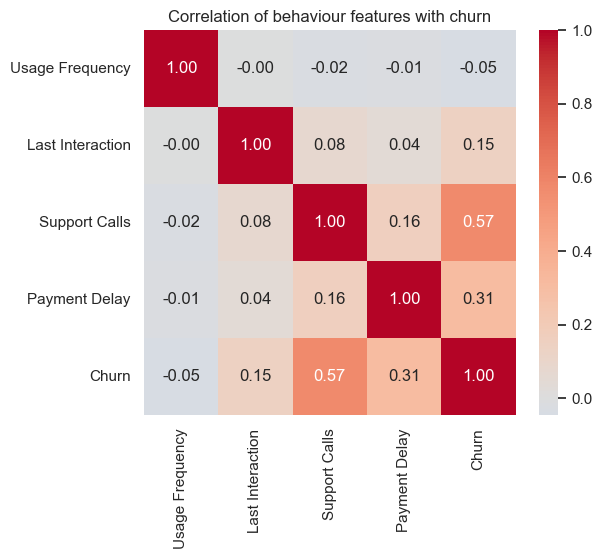

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["Support Calls", "Payment Delay", "Usage Frequency"]):
    sns.kdeplot(data=train, x=col, hue="Churn", fill=True, common_norm=False,
                palette={0: "#2a9d8f", 1: "#e63946"}, ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

corr = train[FEATURES + ["Churn"]].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of behaviour features with churn")
plt.show()


## K-MEANS SEGMENTATION Engagement + support tickets + payment delays

In [24]:
scaler = StandardScaler()
X_train = scaler.fit_transform(train[FEATURES])
X_test  = scaler.transform(test[FEATURES]) 

In [25]:
# --- choose k: elbow + silhouette (silhouette on a sample for speed) ---
k_range = range(2, 9)
inertias, sil_scores = [], []
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X_train), size=min(20000, len(X_train)), replace=False)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_train)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_train[sample_idx], km.labels_[sample_idx]))

fig = go.Figure()
fig.add_trace(go.Scatter(x=list(k_range), y=inertias, mode="lines+markers",
                         name="Inertia (elbow)", yaxis="y1"))
fig.add_trace(go.Scatter(x=list(k_range), y=sil_scores, mode="lines+markers",
                         name="Silhouette", yaxis="y2"))
fig.update_layout(title="Choosing k: elbow and silhouette",
                  xaxis_title="Number of clusters (k)",
                  yaxis=dict(title="Inertia"),
                  yaxis2=dict(title="Silhouette", overlaying="y", side="right"),
                  template="plotly_white")
fig.show()

best_k = N_CLUSTERS_OVERRIDE or list(k_range)[int(np.argmax(sil_scores))]
print("Using k =", best_k)

kmeans = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit(X_train)
train["Cluster"] = kmeans.labels_
test["Cluster"]  = kmeans.predict(X_test)



Using k = 2


## profile segmentation of high risk


Segment profile (sorted by churn rate):
                 Customers  Usage  DaysSinceInteraction  SupportCalls  \
Cluster                                                                 
High-risk           154931  15.19                 16.58          7.00   
Loyal / healthy     285901  16.14                 13.34          1.76   

                 PaymentDelay  ChurnRate  
Cluster                                   
High-risk               17.16       0.97  
Loyal / healthy         10.69       0.35  


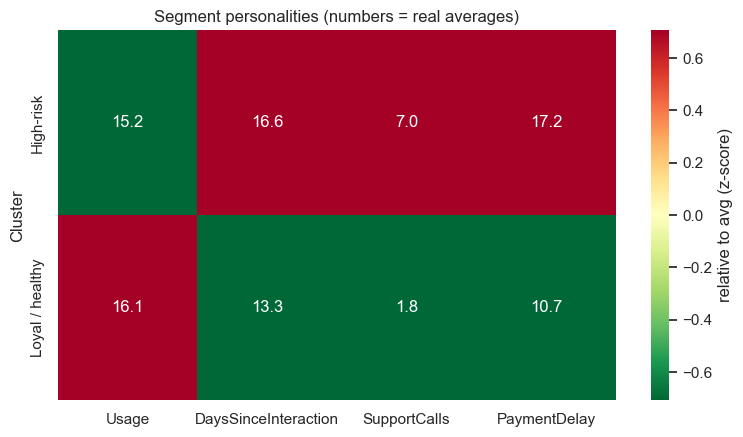

In [26]:
# =====================================================
# 4. PROFILE SEGMENTS & NAME THE HIGH-RISK GROUP
#    (Churn is used only to INTERPRET clusters, never to build them)
# =====================================================
profile = (train.groupby("Cluster")
                .agg(Customers=("CustomerID", "count"),
                     Usage=("Usage Frequency", "mean"),
                     DaysSinceInteraction=("Last Interaction", "mean"),
                     SupportCalls=("Support Calls", "mean"),
                     PaymentDelay=("Payment Delay", "mean"),
                     ChurnRate=("Churn", "mean"))
                .round(2)
                .sort_values("ChurnRate", ascending=False))

HIGH_RISK = profile.index[0]   # cluster with highest churn rate

# readable names: rank by churn rate
rank_names = {}
for i, c in enumerate(profile.index):
    if i == 0:
        rank_names[c] = "High-risk"
    elif i == len(profile) - 1:
        rank_names[c] = "Loyal / healthy"
    else:
        rank_names[c] = f"Watch-list {i}"
train["Segment"] = train["Cluster"].map(rank_names)
test["Segment"]  = test["Cluster"].map(rank_names)

print("\nSegment profile (sorted by churn rate):")
print(profile.rename(index=rank_names))

# seaborn heatmap of the standardized profile
prof_z = profile.drop(columns=["Customers", "ChurnRate"])
prof_z = (prof_z - prof_z.mean()) / prof_z.std()
plt.figure(figsize=(9, 4 + 0.4 * best_k))
sns.heatmap(prof_z.rename(index=rank_names), annot=profile.drop(columns=["Customers", "ChurnRate"]).rename(index=rank_names),
            fmt=".1f", cmap="RdYlGn_r", center=0, cbar_kws={"label": "relative to avg (z-score)"})
plt.title("Segment personalities (numbers = real averages)")
plt.show()

# churn rate per segment
seg_churn = (train.groupby("Segment")["Churn"].mean().sort_values(ascending=False)
                   .reset_index())
fig = px.bar(seg_churn, x="Segment", y="Churn", text=seg_churn["Churn"].map("{:.0%}".format),
             color="Churn", color_continuous_scale="RdYlGn_r",
             title="Churn rate by K-Means segment (training data)")
fig.update_layout(template="plotly_white", yaxis_tickformat=".0%")
fig.show()

# interactive 3D view of the segments
plot_df = train.sample(min(15000, len(train)), random_state=RANDOM_STATE)
fig = px.scatter_3d(plot_df, x="Support Calls", y="Payment Delay", z="Usage Frequency",
                    color="Segment", opacity=0.6, hover_data=["CustomerID", "Churn"],
                    title="Customer segments in behaviour space")
fig.update_traces(marker=dict(size=2.5))
fig.show()



## who is drifting towards high risk

In [27]:
# =====================================================
# 5. KNN: "WHO IS DRIFTING TOWARD THE HIGH-RISK GROUP?"
#    Train KNN to recognise the high-risk neighbourhood.
#    predict_proba = share of the K nearest customers who sit in high-risk.
#    That share is the DRIFT SCORE.
# =====================================================
y_train_hr = (train["Cluster"] == HIGH_RISK).astype(int)

knn = KNeighborsClassifier(n_neighbors=KNN_NEIGHBORS, n_jobs=-1)
knn.fit(X_train, y_train_hr)

def score_customers(df, X):
    out = df.copy()
    out["DriftScore"] = knn.predict_proba(X)[:, 1]
    out["InHighRisk"] = (out["Cluster"] == HIGH_RISK)
    # drifting = NOT yet in high-risk cluster, but neighbourhood is turning red
    out["Drifting"] = (~out["InHighRisk"]) & (out["DriftScore"] >= DRIFT_THRESHOLD)
    out["Status"] = np.select(
        [out["InHighRisk"], out["Drifting"]],
        ["Already high-risk", "Drifting: act now"],
        default="Stable"
    )
    return out

# Simulate production: score every test customer as if it were today's snapshot
scored = score_customers(test, X_test)

print("\nStatus counts (test):")
print(scored["Status"].value_counts())

fig = px.histogram(scored, x="DriftScore", color="Status", nbins=40, barmode="overlay",
                   opacity=0.7, title="Drift score distribution (share of neighbours in high-risk group)",
                   color_discrete_map={"Stable": "#2a9d8f",
                                       "Drifting: act now": "#f4a261",
                                       "Already high-risk": "#e63946"})
fig.add_vline(x=DRIFT_THRESHOLD, line_dash="dash", annotation_text="Alert threshold")
fig.update_layout(template="plotly_white")
fig.show()



Status counts (test):
Status
Already high-risk    42614
Stable               21459
Drifting: act now      301
Name: count, dtype: int64


## Flag actually matters?

In [28]:
# =====================================================
# 6. DOES THE FLAG ACTUALLY MATTER? (validate on real outcomes)
#    A flag is only useful if flagged customers churn more than the rest.
# =====================================================
status_summary = (scored.groupby("Status")
                        .agg(Customers=("CustomerID", "count"),
                             ChurnRate=("Churn", "mean"))
                        .reset_index())
base = scored["Churn"].mean()
status_summary["Lift_vs_avg"] = (status_summary["ChurnRate"] / base).round(2)
print("\nValidation on test set (baseline churn = {:.1%}):".format(base))
print(status_summary)

fig = px.bar(status_summary, x="Status", y="ChurnRate",
             text=status_summary["ChurnRate"].map("{:.0%}".format),
             color="Status",
             color_discrete_map={"Stable": "#2a9d8f",
                                 "Drifting: act now": "#f4a261",
                                 "Already high-risk": "#e63946"},
             title="Actual churn rate by status (test set)")
fig.add_hline(y=base, line_dash="dash", annotation_text=f"Average {base:.0%}")
fig.update_layout(template="plotly_white", yaxis_tickformat=".0%", showlegend=False)
fig.show()

# Capacity view: account managers can only call N accounts per week.
# Rank drifting accounts by score and check precision of the top N.
drifters = scored[scored["Drifting"]].sort_values("DriftScore", ascending=False)
top_n = drifters.head(CAPACITY_PER_WEEK)
print(f"\nTop {len(top_n)} drifting accounts -> actual churn rate: {top_n['Churn'].mean():.1%} "
      f"(vs {base:.1%} overall)")

# Lift curve across all drifting accounts
drifters = drifters.reset_index(drop=True)
drifters["CumChurnCaptured"] = drifters["Churn"].cumsum() / max(drifters["Churn"].sum(), 1)
drifters["PctContacted"] = (drifters.index + 1) / len(drifters)
fig = px.line(drifters, x="PctContacted", y="CumChurnCaptured",
              title="If managers call accounts in drift-score order, how many future churners do they reach?")
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines",
                         line=dict(dash="dash", color="grey"), name="Random calling"))
fig.update_layout(template="plotly_white", xaxis_tickformat=".0%", yaxis_tickformat=".0%",
                  xaxis_title="% of drifting accounts contacted",
                  yaxis_title="% of churners reached")
fig.show()




Validation on test set (baseline churn = 47.4%):
              Status  Customers  ChurnRate  Lift_vs_avg
0  Already high-risk      42614   0.622917         1.32
1  Drifting: act now        301   0.308970         0.65
2             Stable      21459   0.179645         0.38



Top 301 drifting accounts -> actual churn rate: 30.9% (vs 47.4% overall)


In [30]:
# =====================================================
# 7. THE DECISION: ACCOUNT MANAGER WORKLIST
#    Output the model exists to produce.
# =====================================================
def main_driver(row):
    # which behaviour is furthest above the healthy-segment average
    healthy = train.loc[train["Segment"] == "Loyal / healthy", FEATURES].mean()
    gaps = {
        "High support calls":     (row["Support Calls"]    - healthy["Support Calls"])   / train["Support Calls"].std(),
        "Late payments":          (row["Payment Delay"]    - healthy["Payment Delay"])   / train["Payment Delay"].std(),
        "Low usage":              (healthy["Usage Frequency"] - row["Usage Frequency"])  / train["Usage Frequency"].std(),
        "Long silence":           (row["Last Interaction"] - healthy["Last Interaction"])/ train["Last Interaction"].std(),
    }
    return max(gaps, key=gaps.get)

def recommended_action(driver, score):
    discount = "20%" if score >= 0.6 else "10%"
    return {
        "High support calls": f"Call to resolve open issues + {discount} loyalty discount",
        "Late payments":      f"Offer flexible payment plan + {discount} loyalty discount",
        "Low usage":          f"Onboarding / feature check-in + {discount} loyalty discount",
        "Long silence":       f"Personal re-engagement call + {discount} loyalty discount",
    }[driver]

worklist = top_n.copy()
worklist["MainDriver"] = worklist.apply(main_driver, axis=1)
worklist["RecommendedAction"] = [recommended_action(d, s) for d, s in zip(worklist["MainDriver"], worklist["DriftScore"])]

worklist_cols = ["CustomerID", "Segment", "DriftScore", "Support Calls", "Payment Delay",
                 "Usage Frequency", "Last Interaction", "Subscription Type", "Contract Length",
                 "Total Spend", "MainDriver", "RecommendedAction"]
worklist = worklist[worklist_cols].round(2)
worklist.to_csv("account_manager_worklist.csv", index=False)

print("\nSample of the worklist handed to account managers:")
print(worklist.head(10).to_string(index=False))

fig = px.histogram(worklist, x="MainDriver", color="MainDriver",
                   title="Why are these accounts drifting? (main driver)")
fig.update_layout(template="plotly_white", showlegend=False)
fig.show()

print("\nSaved: account_manager_worklist.csv")
print(f"Accounts to contact this week: {len(worklist)} | "
      f"Potential revenue at stake (Total Spend): {worklist['Total Spend'].sum():,.0f}")



Sample of the worklist handed to account managers:
 CustomerID         Segment  DriftScore  Support Calls  Payment Delay  Usage Frequency  Last Interaction Subscription Type Contract Length  Total Spend         MainDriver                                    RecommendedAction
      56413 Loyal / healthy        0.72              2             25                6                18           Premium         Monthly          612      Late payments   Offer flexible payment plan + 20% loyalty discount
      47636 Loyal / healthy        0.72              4             12                1                19           Premium          Annual          130          Low usage Onboarding / feature check-in + 20% loyalty discount
       8847 Loyal / healthy        0.68              6              1               26                25             Basic         Monthly          237 High support calls   Call to resolve open issues + 20% loyalty discount
      36451 Loyal / healthy        0.68             


Saved: account_manager_worklist.csv
Accounts to contact this week: 301 | Potential revenue at stake (Total Spend): 162,132


C:\Users\Fast\AppData\Local\Temp\ipykernel_20220\2309856402.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=status_summary, x="Status", y="ChurnRate",


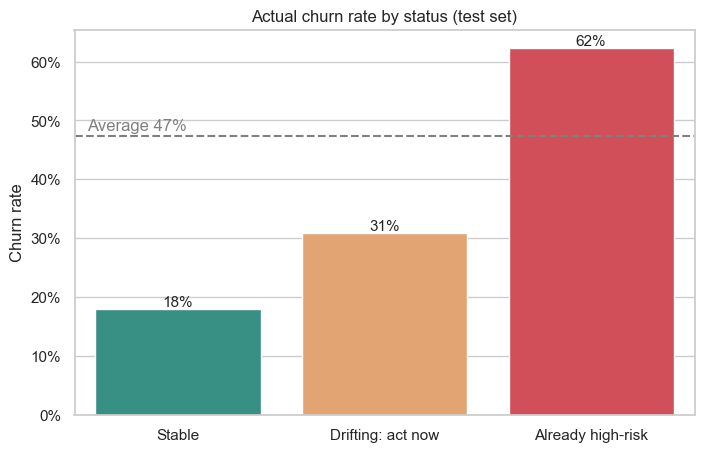

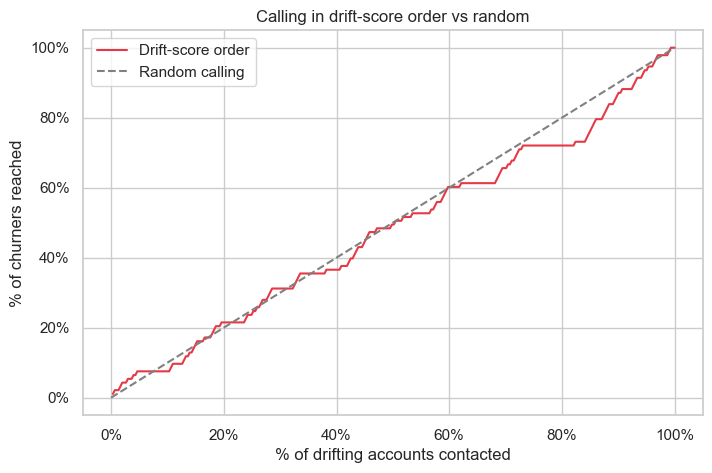

['lift_curve.png', 'status_churn_rate.png']


In [33]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("images", exist_ok=True)

# ---------- Image 1: actual churn rate by status ----------
order = ["Stable", "Drifting: act now", "Already high-risk"]
colors = {"Stable": "#2a9d8f", "Drifting: act now": "#f4a261", "Already high-risk": "#e63946"}

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=status_summary, x="Status", y="ChurnRate",
                 order=[o for o in order if o in status_summary["Status"].values],
                 palette=colors)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
plt.axhline(base, ls="--", color="grey")
plt.text(0.02, base + 0.01, f"Average {base:.0%}", color="grey",
         transform=plt.gca().get_yaxis_transform())
plt.title("Actual churn rate by status (test set)")
plt.ylabel("Churn rate")
plt.xlabel("")
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.savefig("images/status_churn_rate.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------- Image 2: lift curve ----------
plt.figure(figsize=(8, 5))
plt.plot(drifters["PctContacted"], drifters["CumChurnCaptured"], label="Drift-score order", color="#e63946")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random calling")
plt.xlabel("% of drifting accounts contacted")
plt.ylabel("% of churners reached")
plt.title("Calling in drift-score order vs random")
plt.gca().xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.legend()
plt.savefig("images/lift_curve.png", dpi=200, bbox_inches="tight")
plt.show()

print(os.listdir("images"))